# 💧 Water Quality Classification Using Logistic Regression and Decision Trees

## Project Objective

The objective of this project is to classify water as **Potable** or **Not Potable** using machine learning techniques.

Two classification algorithms are used:

1. Logistic Regression
2. Decision Tree Classifier

The models use different water-quality parameters to learn patterns from the dataset and predict whether a water sample is potable.

---

## Dataset

The dataset contains water-quality measurements such as:

- pH
- Hardness
- Solids
- Chloramines
- Sulfate
- Conductivity
- Organic Carbon
- Trihalomethanes
- Turbidity

The target variable is **Potability**:

- `0` → Not Potable
- `1` → Potable

---

## Methodology

The project follows these steps:

1. Load the dataset
2. Explore the dataset
3. Handle missing values
4. Analyze the distribution of water potability
5. Split the data into training and testing sets
6. Apply feature scaling
7. Train Logistic Regression
8. Train Decision Tree
9. Evaluate both models
10. Compare model performance
11. Predict the quality of new water samples

# Conclusion

This project demonstrates the use of machine learning for water quality classification.

Logistic Regression and Decision Tree algorithms were trained using water-quality parameters. Their performance was evaluated using accuracy, classification reports, and confusion matrices.

For the current test data, Logistic Regression achieved an accuracy of approximately **62.80%**, while the Decision Tree achieved approximately **57.77%**.

The models can also be used to classify new water-quality measurements as **Potable** or **Not Potable**.

Overall, the project shows how machine learning can be applied to analyze water-quality data and perform basic classification.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [24]:
!wget -O /content/water_potability.csv "https://raw.githubusercontent.com/prasadposture/Water-Potability-Project/main/water_potability.csv"

--2026-08-12 15:53:08--  https://raw.githubusercontent.com/prasadposture/Water-Potability-Project/main/water_potability.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 344703 (337K) [text/plain]
Saving to: ‘/content/water_potability.csv’

/content/water_pota 100%[===================>] 336.62K  --.-KB/s    in 0.1s    

2026-08-12 15:53:08 (2.78 MB/s) - ‘/content/water_potability.csv’ saved [344703/344703]



In [25]:
df = pd.read_csv('/content/water_potability.csv')
display(df.head())
display(df.info())

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890456,20791.31898,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.05786,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.54173,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.41744,8.059332,356.886136,363.266516,18.436525,100.341674,4.628771,0
4,9.092223,181.101509,17978.98634,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


None

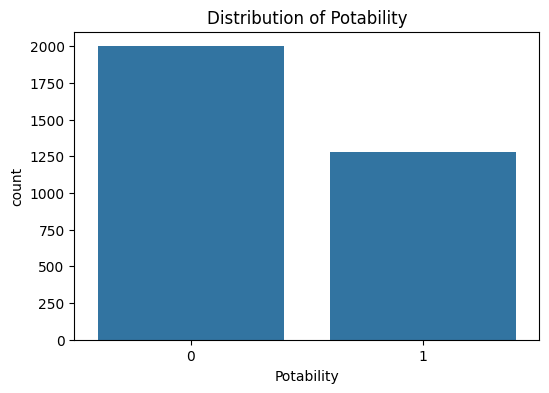

Missing values handled and data distribution visualized.


In [26]:
# Handling missing values by filling them with the mean
df['ph'] = df['ph'].fillna(df['ph'].mean())
df['Sulfate'] = df['Sulfate'].fillna(df['Sulfate'].mean())
df['Trihalomethanes'] = df['Trihalomethanes'].fillna(df['Trihalomethanes'].mean())

# Check class balance
plt.figure(figsize=(6, 4))
sns.countplot(x='Potability', data=df)
plt.title('Distribution of Potability')
plt.show()

print("Missing values handled and data distribution visualized.")

In [27]:
# Splitting the data into features (X) and target (y)
X = df.drop('Potability', axis=1)
y = df['Potability']

# Splitting into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Logistic Regression
lr_model = LogisticRegression()
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)

# 2. Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_preds))
print("\nLogistic Regression Report:\n", classification_report(y_test, lr_preds))

print("-" * 30)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_preds))
print("\nDecision Tree Report:\n", classification_report(y_test, dt_preds))

Logistic Regression Accuracy: 0.6280487804878049

Logistic Regression Report:
               precision    recall  f1-score   support

           0       0.63      1.00      0.77       412
           1       0.00      0.00      0.00       244

    accuracy                           0.63       656
   macro avg       0.31      0.50      0.39       656
weighted avg       0.39      0.63      0.48       656

------------------------------
Decision Tree Accuracy: 0.5777439024390244

Decision Tree Report:
               precision    recall  f1-score   support

           0       0.68      0.62      0.65       412
           1       0.44      0.51      0.47       244

    accuracy                           0.58       656
   macro avg       0.56      0.56      0.56       656
weighted avg       0.59      0.58      0.58       656



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


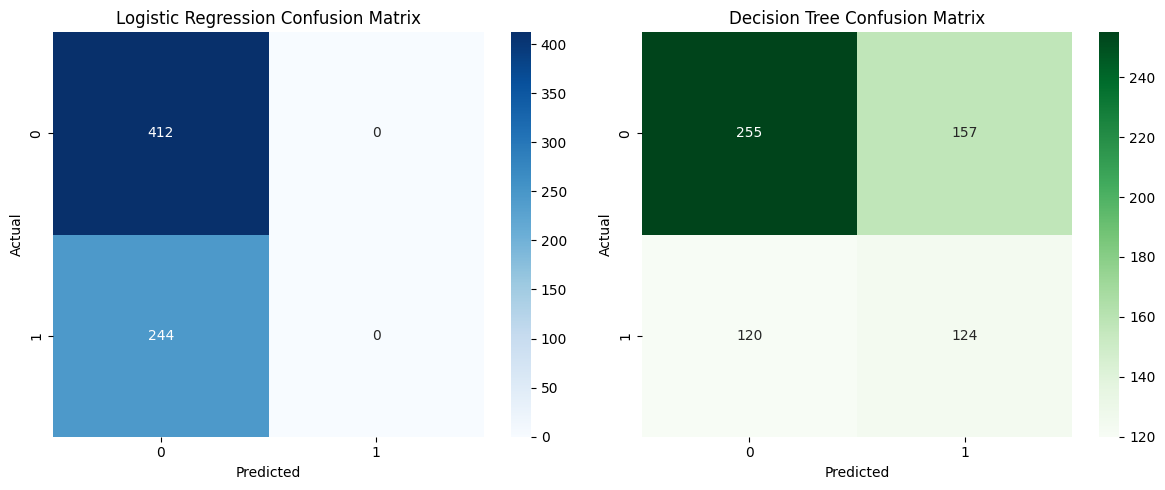

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression Confusion Matrix
sns.heatmap(confusion_matrix(y_test, lr_preds), annot=True, fmt='d', ax=ax[0], cmap='Blues')
ax[0].set_title('Logistic Regression Confusion Matrix')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

# Decision Tree Confusion Matrix
sns.heatmap(confusion_matrix(y_test, dt_preds), annot=True, fmt='d', ax=ax[1], cmap='Greens')
ax[1].set_title('Decision Tree Confusion Matrix')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

Model Performance Comparison:


,Model,Accuracy
0,Logistic Regression,0.628049
1,Decision Tree,0.577744


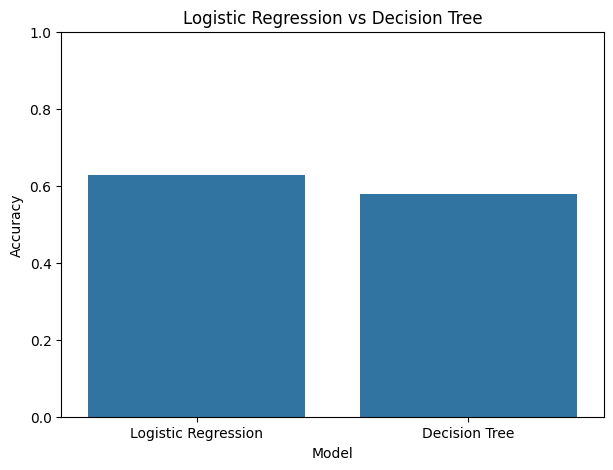

In [29]:
# Model Comparison

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, lr_preds),
        accuracy_score(y_test, dt_preds)
    ]
})

print("Model Performance Comparison:")
display(results)

# Accuracy comparison graph
plt.figure(figsize=(7, 5))
sns.barplot(x='Model', y='Accuracy', data=results)
plt.title('Logistic Regression vs Decision Tree')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

In [30]:
# Water Quality Prediction

print("Enter water quality values:")

ph = float(input("pH: "))
hardness = float(input("Hardness: "))
solids = float(input("Solids: "))
chloramines = float(input("Chloramines: "))
sulfate = float(input("Sulfate: "))
conductivity = float(input("Conductivity: "))
organic_carbon = float(input("Organic Carbon: "))
trihalomethanes = float(input("Trihalomethanes: "))
turbidity = float(input("Turbidity: "))

# Create input data
new_water = pd.DataFrame([[
    ph, hardness, solids, chloramines, sulfate,
    conductivity, organic_carbon, trihalomethanes, turbidity
]], columns=X.columns)

# Scale the input for Logistic Regression
new_water_scaled = scaler.transform(new_water)

# Predictions
lr_prediction = lr_model.predict(new_water_scaled)[0]
dt_prediction = dt_model.predict(new_water)[0]

print("\n--- Prediction Results ---")

if lr_prediction == 1:
    print("Logistic Regression: POTABLE")
else:
    print("Logistic Regression: NOT POTABLE")

if dt_prediction == 1:
    print("Decision Tree: POTABLE")
else:
    print("Decision Tree: NOT POTABLE")


Enter water quality values:
pH: 7
Hardness: 200
Solids: 20000
Chloramines: 7
Sulfate: 330
Conductivity: 400
Organic Carbon: 15
Trihalomethanes: 60
Turbidity: 4

--- Prediction Results ---
Logistic Regression: NOT POTABLE
Decision Tree: NOT POTABLE


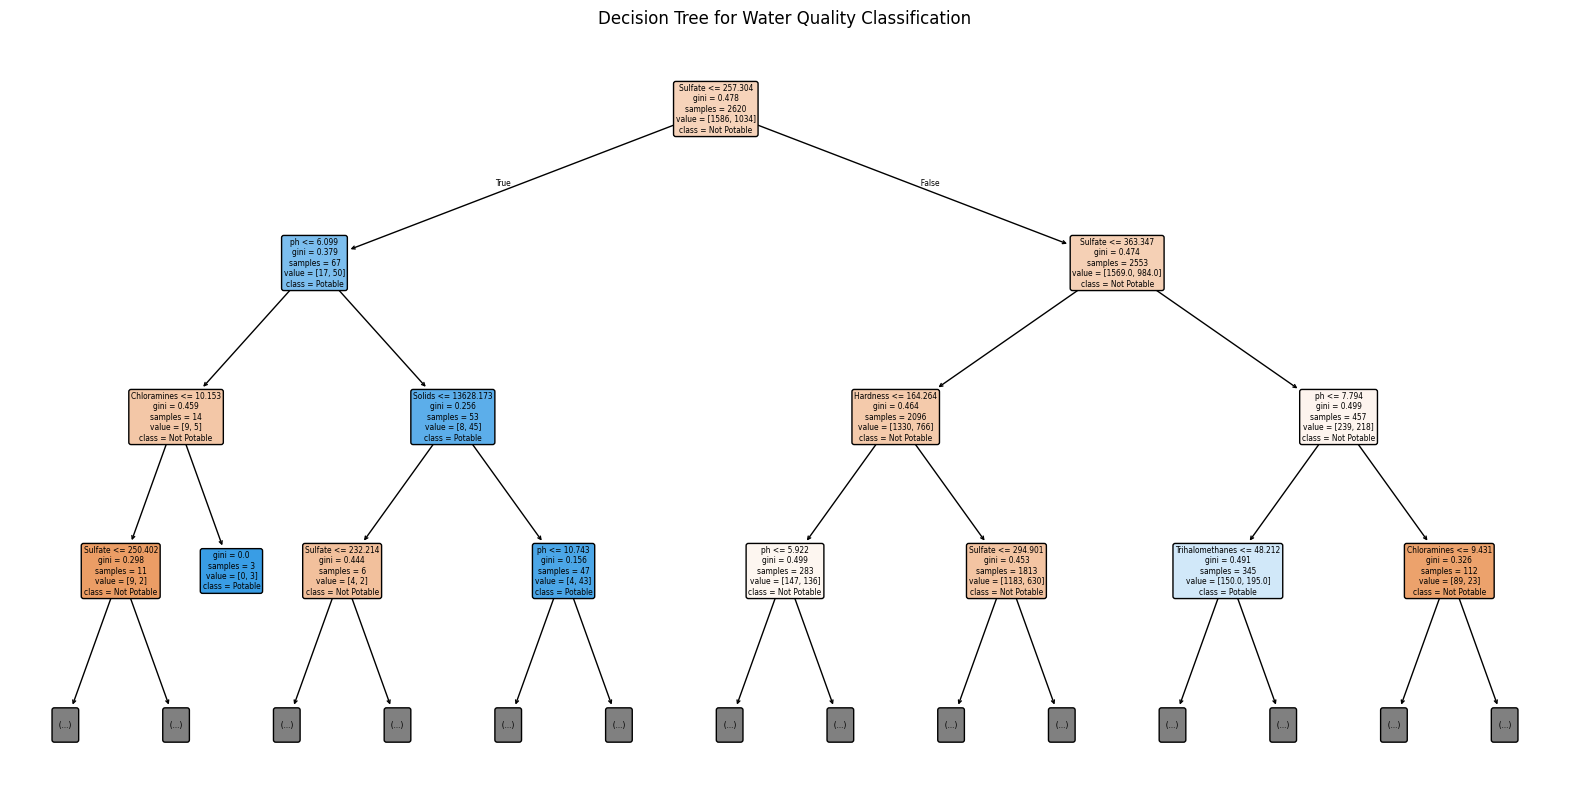

In [31]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["Not Potable", "Potable"],
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title("Decision Tree for Water Quality Classification")
plt.show()